# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** EKO APRILIYANI
- **Email:** ekoapriliyani@gmail.com
- **Email Dicoding:** ds496b6y0503@student.devacademy.id
- **ID Dicoding:** DS496B6Y0503

## Menentukan Pertanyaan Bisnis

Konteks: Olist adalah marketplace Brasil yang menghubungkan penjual dengan pembeli. Periode analisis dibatasi **Januari 2017 – Agustus 2018** karena data 2016 dan September–Oktober 2018 sangat sedikit (tidak mewakili kondisi normal), dan hanya pesanan berstatus **delivered** yang dihitung.

- **Pertanyaan 1:** Kategori produk apa saja yang menghasilkan total revenue (jumlah `price`) tertinggi dan terendah pada pesanan *delivered* periode Januari 2017 – Agustus 2018, dan bagaimana tren revenue bulanan 5 kategori teratas, sehingga tim merchandising dapat menentukan kategori prioritas untuk stok dan promosi?
- **Pertanyaan 2:** Seberapa besar penurunan rata-rata review score (skala 1–5) pada pesanan yang terlambat dibanding yang tepat waktu (tanggal diterima > estimasi) pada periode Januari 2017 – Agustus 2018, dan di 10 *state* mana persentase keterlambatan tertinggi, sehingga tim logistik dapat memprioritaskan perbaikan layanan pengiriman?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
%matplotlib inline

## Data Wrangling

### Gathering Data

#### Load seluruh tabel dataset

In [2]:
path = "data/"

customers = pd.read_csv(path + "customers_dataset.csv")
geolocation = pd.read_csv(path + "geolocation_dataset.csv")
order_items = pd.read_csv(path + "order_items_dataset.csv")
order_payments = pd.read_csv(path + "order_payments_dataset.csv")
order_reviews = pd.read_csv(path + "order_reviews_dataset.csv")
orders = pd.read_csv(path + "orders_dataset.csv")
products = pd.read_csv(path + "products_dataset.csv")
sellers = pd.read_csv(path + "sellers_dataset.csv")
# file ini diawali BOM, sehingga memakai encoding utf-8-sig
translation = pd.read_csv(path + "product_category_name_translation.csv", encoding="utf-8-sig")

tables = {"customers": customers, "geolocation": geolocation, "order_items": order_items,
          "order_payments": order_payments, "order_reviews": order_reviews, "orders": orders,
          "products": products, "sellers": sellers, "translation": translation}
pd.DataFrame({k: v.shape for k, v in tables.items()}, index=["baris", "kolom"]).T

,baris,kolom
customers,99441,5
geolocation,1000163,5
order_items,112650,7
order_payments,103886,5
order_reviews,99224,7
orders,99441,8
products,32951,9
sellers,3095,4
translation,71,2


In [3]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Terdapat 9 tabel yang saling berelasi: `orders` menjadi pusat, terhubung ke `customers` (via `customer_id`), `order_items` (via `order_id`), `order_reviews`, dan `order_payments`; `order_items` terhubung ke `products` dan `sellers`.
- Tabel `translation` dipakai untuk mengubah nama kategori produk dari bahasa Portugis ke Inggris.

### Assessing Data

#### Memeriksa tipe data, missing value, dan duplikasi

In [4]:
for name, df in tables.items():
    miss = df.isna().sum()
    print(f"== {name} | shape={df.shape} | duplikat={df.duplicated().sum()}")
    print(miss[miss > 0].to_string() if miss.sum() else "tidak ada missing value")
    print()

== customers | shape=(99441, 5) | duplikat=0
tidak ada missing value



== geolocation | shape=(1000163, 5) | duplikat=261831
tidak ada missing value

== order_items | shape=(112650, 7) | duplikat=0
tidak ada missing value

== order_payments | shape=(103886, 5) | duplikat=0
tidak ada missing value

== order_reviews | shape=(99224, 7) | duplikat=0
review_comment_title      87656
review_comment_message    58247

== orders | shape=(99441, 8) | duplikat=0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

== products | shape=(32951, 9) | duplikat=0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2

== sellers | shape=(3095, 4) | duplikat=0
tidak ada missing value

== translation | shape=(71, 2) | duplikat=0
tidak ada missing value



In [5]:
orders.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

#### Memeriksa invalid / inaccurate / inconsistent value

In [6]:
print("Status pesanan:")
print(orders["order_status"].value_counts(), "\n")

# pesanan 'delivered' tetapi tanggal diterima kosong
print("delivered tanpa tanggal diterima:",
      ((orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()).sum())

# review ganda untuk satu pesanan
print("order_id yang punya >1 review:", order_reviews["order_id"].duplicated().sum())

# bobot produk 0 gram (tidak masuk akal)
print("produk dengan berat 0 gram:", (products["product_weight_g"] == 0).sum())

# kategori produk yang tidak ada di tabel terjemahan
print("kategori tanpa terjemahan:",
      set(products["product_category_name"].dropna()) - set(translation["product_category_name"]))

# rentang waktu pesanan per bulan
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
orders.groupby(orders["order_purchase_timestamp"].dt.to_period("M")).size().iloc[[0, 1, 2, 3, -3, -2, -1]]

Status pesanan:


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

delivered tanpa tanggal diterima: 8
order_id yang punya >1 review: 551
produk dengan berat 0 gram: 4
kategori tanpa terjemahan: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64

**Steps to Take (masalah yang ditemukan → tindakan di tahap cleaning):**
- **Missing value** pada `orders` (`order_approved_at` 160, `order_delivered_carrier_date` 1.783, `order_delivered_customer_date` 2.965): pesanan non-*delivered* memang belum punya tanggal diterima → analisis dibatasi pada `delivered`. Terdapat 8 pesanan *delivered* tanpa tanggal diterima → dibuang karena keterlambatan tidak bisa dihitung.
- **Missing value** pada `products` (610 kategori kosong): isi dengan label `unknown`. Dua kategori tidak punya terjemahan (`pc_gamer`, `portateis_cozinha_e_preparadores_de_alimentos`) → tambahkan terjemahan manual.
- **Duplicate data**: `geolocation` memiliki 261.831 baris duplikat → `drop_duplicates()`. Tabel `order_reviews` memiliki 551 pesanan dengan lebih dari satu review → ambil review terbaru per pesanan agar tidak menggandakan baris saat merge.
- **Inaccurate value**: 4 produk berberat 0 gram → diubah menjadi `NaN`.
- **Tipe data**: kolom tanggal masih bertipe `object` → konversi ke `datetime`.
- **Outlier waktu**: data 2016 dan Sep–Okt 2018 sangat sedikit → analisis dibatasi Januari 2017 – Agustus 2018.

### Cleaning Data

#### Memperbaiki tipe data, duplikasi, missing value, dan nilai tidak akurat

In [7]:
# 1. Tipe data tanggal
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])
order_reviews["review_answer_timestamp"] = pd.to_datetime(order_reviews["review_answer_timestamp"])

# 2. Duplikasi
geolocation = geolocation.drop_duplicates()
order_reviews = (order_reviews.sort_values("review_answer_timestamp")
                 .drop_duplicates(subset="order_id", keep="last"))

# 3. Nilai tidak akurat (berat 0 gram)
products.loc[products["product_weight_g"] == 0, "product_weight_g"] = np.nan

# 4. Missing value kategori + terjemahan yang hilang
extra = pd.DataFrame({"product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
                      "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers"]})
translation = pd.concat([translation, extra], ignore_index=True)
products = products.merge(translation, on="product_category_name", how="left")
products["category"] = products["product_category_name_english"].fillna("unknown")

# 5. Filter pesanan: delivered, punya tanggal diterima, periode Jan 2017 - Agu 2018
orders_clean = orders[(orders["order_status"] == "delivered")].dropna(subset=["order_delivered_customer_date"])
orders_clean = orders_clean[(orders_clean["order_purchase_timestamp"] >= "2017-01-01") &
                            (orders_clean["order_purchase_timestamp"] < "2018-09-01")]

print("duplikat geolocation:", geolocation.duplicated().sum(), "| order_id ganda di review:", order_reviews["order_id"].duplicated().sum())
print("pesanan siap analisis:", len(orders_clean))

duplikat geolocation: 0 | order_id ganda di review: 0
pesanan siap analisis: 96203


#### Menggabungkan tabel menjadi satu dataset utama

In [8]:
main_df = (orders_clean
           .merge(customers, on="customer_id", how="inner")
           .merge(order_items, on="order_id", how="inner")
           .merge(products[["product_id", "category"]], on="product_id", how="left")
           .merge(order_reviews[["order_id", "review_score"]], on="order_id", how="left"))

main_df["order_month"] = main_df["order_purchase_timestamp"].dt.to_period("M").astype(str)
main_df["is_late"] = main_df["order_delivered_customer_date"] > main_df["order_estimated_delivery_date"]
main_df["delay_days"] = (main_df["order_delivered_customer_date"] - main_df["order_estimated_delivery_date"]).dt.days

print(main_df.shape, "| jumlah pesanan unik:", main_df["order_id"].nunique())
print("item tanpa review:", main_df["review_score"].isna().sum())
main_df[["order_id", "category", "price", "review_score", "is_late", "delay_days"]].head()

(109872, 23) | jumlah pesanan unik: 96203
item tanpa review: 823


,order_id,category,price,review_score,is_late,delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,housewares,29.99,4.0,False,-8
1,53cdb2fc8bc7dce0b6741e2150273451,perfumery,118.70,4.0,False,-6
2,47770eb9100c2d0c44946d9cf07ec65d,auto,159.90,5.0,False,-18
3,949d5b44dbf5de918fe9c16f97b45f8a,pet_shop,45.00,5.0,False,-13
4,ad21c59c0840e6cb83a9ceb5573f8159,stationery,19.90,5.0,False,-10


**Insight:**
- Setelah dibersihkan terdapat ±96 ribu pesanan *delivered* (±110 ribu item) pada Jan 2017 – Agu 2018, siap dipakai untuk kedua pertanyaan.
- Review dipilih satu per pesanan sehingga jumlah baris pada hasil merge tidak membengkak.

## Exploratory Data Analysis (EDA)

### Explore Revenue per Kategori Produk (Pertanyaan 1)

In [9]:
category_df = (main_df.groupby("category")
               .agg(total_revenue=("price", "sum"), items_sold=("order_item_id", "count"))
               .sort_values("total_revenue", ascending=False))
category_df["share_pct"] = category_df["total_revenue"] / category_df["total_revenue"].sum() * 100

print("Total revenue:", round(category_df["total_revenue"].sum()))
print("Jumlah kategori:", len(category_df))
print("Kontribusi 5 kategori teratas: %.1f%%" % category_df["share_pct"].head(5).sum())
category_df.head(10).round(1)

Total revenue: 13179778
Jumlah kategori: 74
Kontribusi 5 kategori teratas: 39.9%


,total_revenue,items_sold,share_pct
category,,,
health_beauty,1229557.5,9422,9.3
watches_gifts,1163187.9,5853,8.8
bed_bath_table,1022955.8,10945,7.8
sports_leisure,952661.4,8413,7.2
computers_accessories,887944.6,7631,6.7
furniture_decor,706237.2,8095,5.4
housewares,614341.6,6783,4.7
cool_stuff,609158.0,3711,4.6
auto,577721.1,4131,4.4


In [10]:
category_df.tail(5).round(1)

,total_revenue,items_sold,share_pct
category,,,
flowers,1110.0,33,0.0
home_comfort_2,760.3,30,0.0
cds_dvds_musicals,730.0,14,0.0
fashion_childrens_clothes,520.0,7,0.0
security_and_services,283.3,2,0.0


In [11]:
top5 = category_df.head(5).index
monthly_top5 = (main_df[main_df["category"].isin(top5)]
                .pivot_table(index="order_month", columns="category", values="price", aggfunc="sum")
                .round(0))
monthly_top5.iloc[[0, 5, 10, 11, 12, -1]]

category,bed_bath_table,computers_accessories,health_beauty,sports_leisure,watches_gifts
order_month,,,,,
2017-01,3804.0,3924.0,12366.0,9212.0,8087.0
2017-06,33803.0,36194.0,31677.0,32067.0,27338.0
2017-11,87958.0,69676.0,78274.0,62686.0,95292.0
2017-12,50081.0,37429.0,60689.0,58722.0,69557.0
2018-01,75408.0,80504.0,71406.0,86173.0,73521.0
2018-08,60891.0,40053.0,119391.0,50860.0,69767.0


### Explore Keterlambatan Pengiriman vs Review Score (Pertanyaan 2)

In [12]:
order_df = main_df.drop_duplicates("order_id").copy()   # 1 baris per pesanan
order_df["delay_bucket"] = pd.cut(order_df["delay_days"], bins=[-999, 0, 3, 7, 999],
                                  labels=["Tepat waktu", "Telat 1-3 hari", "Telat 4-7 hari", "Telat >7 hari"])

print("Persentase pesanan terlambat: %.2f%%" % (order_df["is_late"].mean() * 100))
print(order_df.groupby("is_late")["review_score"].agg(["mean", "count"]).round(2), "\n")
print(order_df.groupby("delay_bucket", observed=True)["review_score"].agg(["mean", "count"]).round(2), "\n")
print("% review rendah (<=2):")
print((order_df.groupby("is_late")["review_score"].apply(lambda s: (s <= 2).mean()) * 100).round(1))

Persentase pesanan terlambat: 8.13%
         mean  count
is_late             
False    4.29  87902
True     2.57   7658 

                mean  count
delay_bucket               
Tepat waktu     4.29  89182
Telat 1-3 hari  3.29   1851
Telat 4-7 hari  2.10   1748
Telat >7 hari   1.70   2779 

% review rendah (<=2):
is_late
False     9.2
True     52.9
Name: review_score, dtype: float64


In [13]:
state_df = (order_df.groupby("customer_state")
            .agg(total_orders=("order_id", "count"), late_pct=("is_late", "mean"), avg_review=("review_score", "mean"))
            .query("total_orders >= 500")      # buang state dengan sampel terlalu kecil
            .sort_values("late_pct", ascending=False))
state_df["late_pct"] = (state_df["late_pct"] * 100).round(1)
state_df.head(10).round(2)

,total_orders,late_pct,avg_review
customer_state,,,
MA,713,19.6,3.83
CE,1273,15.4,3.94
BA,3253,14.0,3.93
RJ,12310,13.5,3.97
PA,942,12.4,3.91
ES,1992,12.2,4.08
MS,701,11.6,4.16
PB,516,11.0,4.07
PE,1587,10.8,4.08


**Insight:**
- 5 kategori teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) menyumbang sekitar 40% dari total revenue ±13,2 juta. Sebaliknya kategori terbawah (mis. `security_and_services`, `fashion_childrens_clothes`) hanya menghasilkan ratusan.
- Revenue hampir semua kategori teratas melonjak pada **November 2017** (periode Black Friday).
- Hanya ±8,1% pesanan terlambat, tetapi rata-rata review-nya sangat rendah (≈2,57) dibanding yang tepat waktu (≈4,29). Semakin lama telatnya, semakin buruk skor: >7 hari rata-rata ≈1,70.
- Persentase keterlambatan tertinggi ada di state Maranhão (MA), Ceará (CE), Bahia (BA), dan Rio de Janeiro (RJ).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk dengan revenue tertinggi/terendah dan tren bulanan Top 5

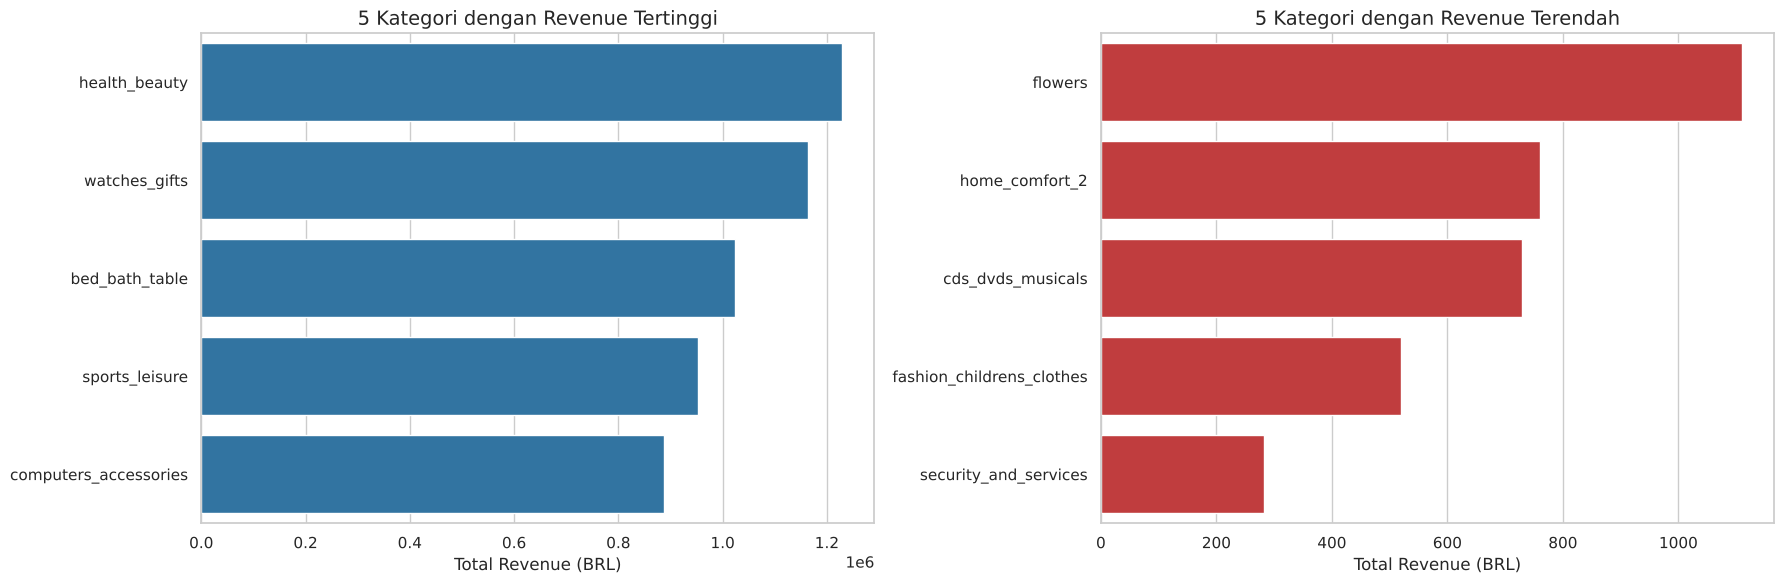

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
colors_top = ["#1f77b4"] + ["#c7d7e8"] * 4

sns.barplot(x="total_revenue", y=category_df.head(5).index, data=category_df.head(5), ax=axes[0],
            palette=["#1f77b4"] * 5, hue=category_df.head(5).index, legend=False)
axes[0].set_title("5 Kategori dengan Revenue Tertinggi", fontsize=14)
axes[0].set_xlabel("Total Revenue (BRL)"); axes[0].set_ylabel("")

sns.barplot(x="total_revenue", y=category_df.tail(5).index, data=category_df.tail(5), ax=axes[1],
            palette=["#d62728"] * 5, hue=category_df.tail(5).index, legend=False)
axes[1].set_title("5 Kategori dengan Revenue Terendah", fontsize=14)
axes[1].set_xlabel("Total Revenue (BRL)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

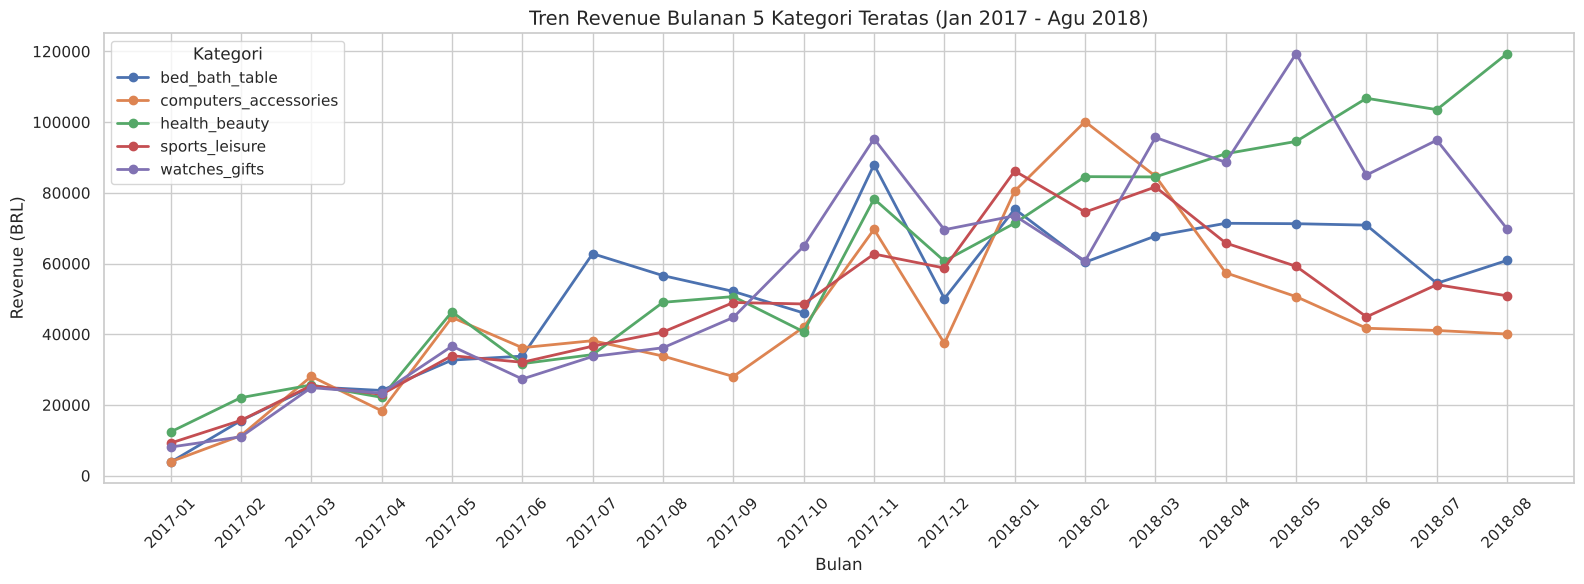

In [15]:
fig, ax = plt.subplots(figsize=(16, 6))
monthly_top5.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Tren Revenue Bulanan 5 Kategori Teratas (Jan 2017 - Agu 2018)", fontsize=14)
ax.set_xlabel("Bulan"); ax.set_ylabel("Revenue (BRL)")
ax.set_xticks(range(len(monthly_top5)))
ax.set_xticklabels(monthly_top5.index, rotation=45)
ax.legend(title="Kategori")
plt.tight_layout(); plt.show()

### Pertanyaan 2: Dampak keterlambatan pengiriman pada review score dan state dengan keterlambatan tertinggi

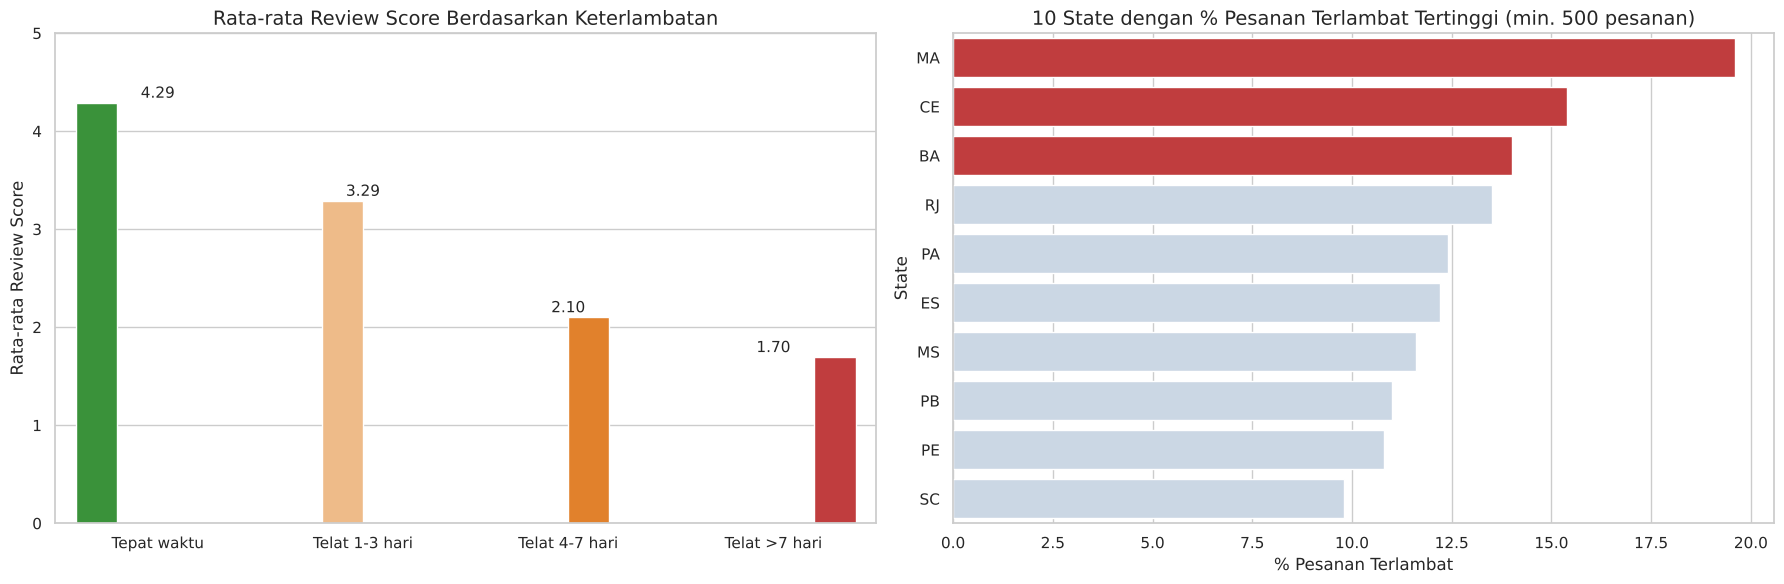

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

delay_review = order_df.groupby("delay_bucket", observed=True)["review_score"].mean().reset_index()
sns.barplot(x="delay_bucket", y="review_score", data=delay_review, ax=axes[0],
            palette=["#2ca02c", "#ffbb78", "#ff7f0e", "#d62728"], hue="delay_bucket", legend=False)
for i, v in enumerate(delay_review["review_score"]):
    axes[0].text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=11)
axes[0].set_title("Rata-rata Review Score Berdasarkan Keterlambatan", fontsize=14)
axes[0].set_xlabel(""); axes[0].set_ylabel("Rata-rata Review Score"); axes[0].set_ylim(0, 5)

top_late = state_df.head(10).reset_index()
sns.barplot(x="late_pct", y="customer_state", data=top_late, ax=axes[1],
            palette=["#d62728"] * 3 + ["#c7d7e8"] * 7, hue="customer_state", legend=False)
axes[1].set_title("10 State dengan % Pesanan Terlambat Tertinggi (min. 500 pesanan)", fontsize=14)
axes[1].set_xlabel("% Pesanan Terlambat"); axes[1].set_ylabel("State")
plt.tight_layout(); plt.show()

**Insight:**
- **P1:** Revenue terkonsentrasi pada segelintir kategori (Top 5 ≈ 40%), dan semuanya memuncak pada November 2017. Kategori `health_beauty` unggul dari sisi revenue, sedangkan `bed_bath_table` unggul dari sisi volume item.
- **P2:** Skor review turun tajam begitu pesanan terlambat: dari ≈4,29 (tepat waktu) menjadi ≈3,29 (telat 1–3 hari) dan ≈1,70 (telat >7 hari). Sekitar 53% pesanan terlambat mendapat review ≤2, dibanding ≈9% pada pesanan tepat waktu.

## Analisis Lanjutan (Opsional)

### RFM Analysis: Segmentasi Pelanggan

RFM dihitung per `customer_unique_id` (pelanggan unik). Karena ±97% pelanggan hanya membeli sekali, skor Frequency tidak dibagi per kuartil, melainkan dipisahkan menjadi pelanggan **repeat (≥2 pesanan)** dan **one-time**. Recency dan Monetary diberi skor 1–4 berdasarkan kuartil.

In [17]:
snapshot = main_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = (main_df.groupby("customer_unique_id")
       .agg(last_purchase=("order_purchase_timestamp", "max"),
            frequency=("order_id", "nunique"),
            monetary=("price", "sum"))
       .reset_index())
rfm["recency"] = (snapshot - rfm["last_purchase"]).dt.days

rfm["r_score"] = pd.qcut(rfm["recency"], 4, labels=[4, 3, 2, 1]).astype(int)     # recency kecil = skor tinggi
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)

def segment(r):
    if r["frequency"] >= 2:
        return "Repeat Customer"
    if r["m_score"] >= 3:
        return "Big Spender - Aktif" if r["r_score"] >= 3 else "Big Spender - Berisiko Hilang"
    return "Pelanggan Baru Bernilai Kecil" if r["r_score"] >= 3 else "Pelanggan Tidak Aktif"

rfm["segment"] = rfm.apply(segment, axis=1)
seg = (rfm.groupby("segment")
       .agg(customers=("customer_unique_id", "count"), avg_recency=("recency", "mean"),
            avg_monetary=("monetary", "mean"))
       .sort_values("customers", ascending=False))
seg["pct"] = seg["customers"] / seg["customers"].sum() * 100
seg.round(1)

,customers,avg_recency,avg_monetary,pct
segment,,,,
Pelanggan Tidak Aktif,23317,362.0,47.2,25.0
Pelanggan Baru Bernilai Kecil,22773,111.2,47.0,24.5
Big Spender - Aktif,22251,111.8,231.5,23.9
Big Spender - Berisiko Hilang,21966,362.5,233.6,23.6
Repeat Customer,2789,219.6,260.1,3.0


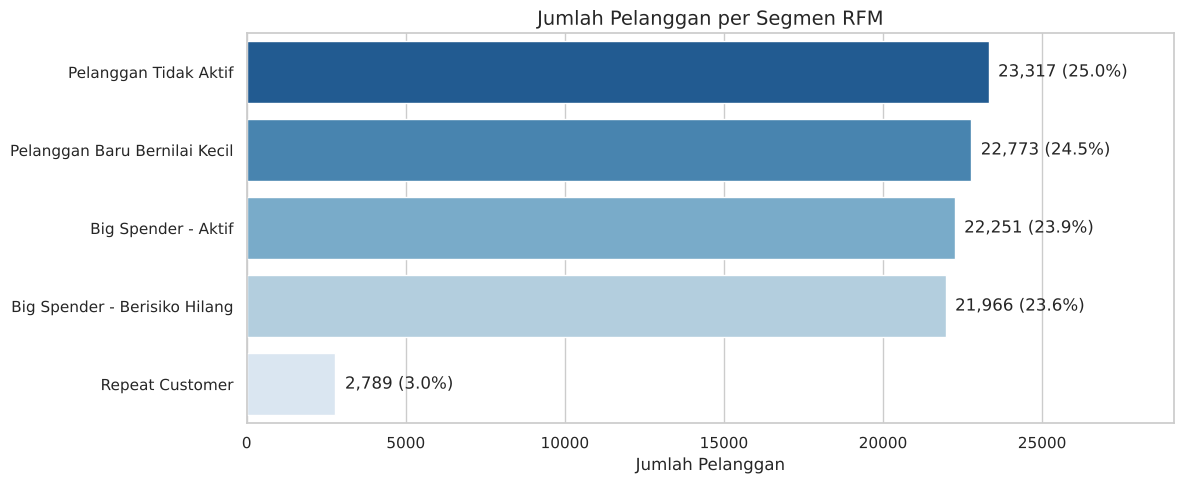

In [18]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x="customers", y=seg.index, data=seg, ax=ax, hue=seg.index, legend=False, palette="Blues_r")
for i, (n, p) in enumerate(zip(seg["customers"], seg["pct"])):
    ax.text(n + 300, i, f"{n:,} ({p:.1f}%)", va="center")
ax.set_title("Jumlah Pelanggan per Segmen RFM", fontsize=14); ax.set_xlabel("Jumlah Pelanggan"); ax.set_ylabel("")
ax.set_xlim(0, seg["customers"].max() * 1.25)
plt.tight_layout(); plt.show()

**Insight:**
- Hanya ±3,0% pelanggan (2.789 orang) yang melakukan pembelian ulang; ±97% hanya membeli sekali. Segmen *Big Spender - Berisiko Hilang* (±23,6%, rata-rata belanja ±234 BRL, terakhir belanja ±362 hari lalu) bernilai tinggi tetapi sudah lama tidak aktif, sehingga menjadi target utama kampanye reaktivasi. Segmen *Big Spender - Aktif* (±23,9%) perlu dijaga agar melakukan pembelian kedua.

### Menyimpan Dataset untuk Dashboard

In [19]:
dashboard_df = main_df[["order_id", "customer_unique_id", "customer_state", "order_purchase_timestamp", "order_month",
                        "category", "price", "freight_value", "review_score", "is_late", "delay_days"]]
dashboard_df.to_csv("dashboard/main_data.csv", index=False)
print(dashboard_df.shape)

(109872, 11)


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama Jan 2017 – Agu 2018, 5 kategori teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) menyumbang ±40% dari total revenue ±13,2 juta BRL, sedangkan kategori terbawah (mis. `security_and_services`, `fashion_childrens_clothes`, `cds_dvds_musicals`) hanya menghasilkan ratusan BRL. Tren bulanan Top 5 naik tajam sepanjang 2017 dan memuncak pada November 2017 (Black Friday), lalu bertahan di level tinggi pada 2018.
- **Conclusion pertanyaan 2:** Keterlambatan pengiriman sangat merusak kepuasan pelanggan. Hanya ±8,1% pesanan yang terlambat, tetapi skor review rata-rata anjlok dari ≈4,29 (tepat waktu) ke ≈2,57 (terlambat), dan ke ≈1,70 bila telat lebih dari 7 hari. Persentase keterlambatan tertinggi ada di state MA (±19,6%), CE (±15,4%), BA (±14,0%), dan RJ (±13,5%).

**Rekomendasi Action Item:**
- **Prioritaskan stok dan promosi** pada 5 kategori teratas, terutama menjelang periode Black Friday (Oktober–November), dan evaluasi kategori berrevenue sangat rendah (tinggalkan, bundling, atau gabungkan ke kategori lain).
- **Perbaiki logistik di state berisiko** (MA, CE, BA, RJ): evaluasi mitra kurir di wilayah tersebut, perbarui estimasi pengiriman agar lebih realistis, dan tambah buffer waktu pada periode puncak.
- **Proaktif menangani pesanan yang berpotensi telat** (kirim notifikasi, voucher kompensasi) untuk menahan penurunan skor review, terutama pada keterlambatan >3 hari yang dampaknya paling besar.
- **Program retensi** untuk segmen *Big Spender – Berisiko Hilang* (kupon pembelian kedua, email re-engagement), karena mayoritas pelanggan hanya membeli sekali.